In [1]:

# ============================================================
# FE5108 Final Project - Part 1
# Question 1E: Regime Sensitivity of Factor Premia
# ============================================================

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

# Locate the project root
current_dir = Path.cwd().resolve()
ROOT = next(
    (p for p in [current_dir, *current_dir.parents]
     if (p / "src" / "config.py").exists()),
    None
)

if ROOT is None:
    raise FileNotFoundError("Project root not found.")

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src import config, utils

config.apply_style()

print("Project root:", ROOT)


Project root: /Users/zhangjiaxin/Desktop/fe5018-final


In [2]:

# Step 2: Load market excess returns and momentum spreads

raw_ff = pd.read_excel(
    config.FILE_FF_MSCI,
    sheet_name=config.SHEET_FF3,
    header=None
)

ff = raw_ff.iloc[4:].copy()
ff.columns = ["Date", "Mkt-RF", "SMB", "HML", "RF"]

# Retain monthly observations only
date_text = ff["Date"].astype(str).str.strip()
mask = date_text.str.fullmatch(r"\d{6}(\.0)?")
ff = ff.loc[mask].copy()

ff["Date"] = ff["Date"].astype(float).astype(int).astype(str)
ff = ff.set_index("Date")

ff = ff.apply(pd.to_numeric, errors="coerce")
ff = utils.pct_to_decimal(ff)
ff = utils.to_monthly_index(ff)

# Load the previously constructed value-weighted momentum spread
factor_spreads = pd.read_csv(
    config.TAB_DIR / "tab_1A_factor_spreads.csv",
    index_col="month"
)

factor_spreads.index = pd.PeriodIndex(
    factor_spreads.index, freq="M"
)

momentum = factor_spreads["Momentum"]

print("Market excess returns:")
display(ff[["Mkt-RF"]].loc["1995-01":"1996-03"])

print("Momentum spreads:")
display(momentum.head())


Market excess returns:


,Mkt-RF
month,
1995-01,0.0180
1995-02,0.0363
1995-03,0.0219
1995-04,0.0211
1995-05,0.0290
1995-06,0.0272
1995-07,0.0372
1995-08,0.0055
1995-09,0.0335


Momentum spreads:


month
1995-01   -0.0346
1995-02    0.0114
1995-03    0.0360
1995-04    0.0194
1995-05   -0.0011
Freq: M, Name: Momentum, dtype: float64

In [3]:

# Step 3: Calculate trailing 12-month market volatility

market_returns = ff["Mkt-RF"].loc[
    "1995-01":"2023-07"
]

# Calculate annualized rolling volatility using 12 monthly returns
rolling_vol = (
    market_returns
    .rolling(window=12, min_periods=12)
    .std(ddof=1)
    * np.sqrt(12)
)

rolling_vol.name = "MarketVol12M"

# Combine volatility and momentum in the same monthly dataset
regime_data = pd.concat(
    [rolling_vol, momentum.rename("Momentum")],
    axis=1
)

regime_data = utils.select_period(regime_data, "1E")

print("Regime analysis dataset:")
display(regime_data.head(10))

print("Sample period:",
      regime_data.index.min(),
      "to", regime_data.index.max())

print("Number of observations:", len(regime_data))
print("Missing values:")
display(regime_data.isna().sum())


Regime analysis dataset:


,MarketVol12M,Momentum
month,,
1995-12,0.054905,0.0110
1996-01,0.054729,0.0253
1996-02,0.053175,-0.0076
1996-03,0.054737,-0.0393
1996-04,0.054721,-0.0391
1996-05,0.053931,0.0414
1996-06,0.060749,0.0269
1996-07,0.092239,0.0055
1996-08,0.094361,0.0119


Sample period: 1995-12 to 2023-07
Number of observations: 332
Missing values:


MarketVol12M    0
Momentum        0
dtype: int64

In [4]:

# Step 4: Validate the rolling volatility calculation

manual_vol = (
    market_returns.loc["1995-01":"1995-12"]
    .std(ddof=1)
    * np.sqrt(12)
)

calculated_vol = regime_data.loc[
    "1995-12", "MarketVol12M"
]

assert np.isclose(manual_vol, calculated_vol)

assert regime_data.index.min() == pd.Period(
    "1995-12", freq="M"
)
assert regime_data.index.max() == pd.Period(
    "2023-07", freq="M"
)
assert len(regime_data) == 332
assert regime_data.index.is_unique
assert regime_data.notna().all().all()

# Save the validated data for subsequent statistical analysis
saved_path = utils.save_table(
    regime_data,
    "tab_1E_regime_data"
)

print("All validation checks passed.")
print(f"Dec 1995 annualized market volatility: {manual_vol:.4%}")
print("Saved:", saved_path)


All validation checks passed.
Dec 1995 annualized market volatility: 5.4905%
Saved: /Users/zhangjiaxin/Desktop/fe5018-final/output/tables/tab_1E_regime_data.csv


In [5]:

# Step 5: Classify market volatility regimes

regime_data["Regime"] = pd.qcut(
    regime_data["MarketVol12M"],
    q=3,
    labels=["Low", "Medium", "High"]
)

regime_summary = (
    regime_data.groupby("Regime", observed=True)
    .agg(
        N=("Momentum", "count"),
        MeanMomentum=("Momentum", "mean"),
        StdMomentum=("Momentum", "std"),
        MeanMarketVol=("MarketVol12M", "mean")
    )
)

# Convert decimal returns and volatility into percentages
regime_summary["Mean Momentum (%)"] = (
    regime_summary["MeanMomentum"] * 100
)

regime_summary["Momentum Std (%)"] = (
    regime_summary["StdMomentum"] * 100
)

regime_summary["Mean Market Vol (%)"] = (
    regime_summary["MeanMarketVol"] * 100
)

summary_display = regime_summary[
    ["N", "Mean Market Vol (%)",
     "Mean Momentum (%)", "Momentum Std (%)"]
]

print("===== MOMENTUM PERFORMANCE BY VOLATILITY REGIME =====")
display(summary_display.round(3))


===== MOMENTUM PERFORMANCE BY VOLATILITY REGIME =====


,N,Mean Market Vol (%),Mean Momentum (%),Momentum Std (%)
Regime,,,,
Low,111,8.209,1.039,4.981
Medium,110,14.189,1.862,7.606
High,111,21.529,-1.028,12.283


In [7]:
# ============================================================
# Step 6: Linear Regression - Momentum vs Market Volatility
# ============================================================

# Define the independent and dependent variables
x = regime_data["MarketVol12M"]
y = regime_data["Momentum"]

# Estimate a simple linear regression
regression = stats.linregress(x, y)

# Extract regression statistics
intercept = regression.intercept
beta = regression.slope
correlation = regression.rvalue
r_squared = regression.rvalue ** 2
p_value = regression.pvalue
t_stat = beta / regression.stderr

# Organize regression results into a table
regression_summary = pd.DataFrame({
    "Metric": [
        "Intercept (alpha)",
        "Volatility coefficient (beta)",
        "t-statistic (beta)",
        "Pearson correlation",
        "R-squared",
        "P-value (beta)",
        "Observations"
    ],
    "Value": [
        intercept,
        beta,
        t_stat,
        correlation,
        r_squared,
        p_value,
        len(regime_data)
    ]
})

print("===== QUESTION 1E: LINEAR REGRESSION RESULTS =====")

display(regression_summary.round(5))

# Display key regression statistics
print(f"\nEstimated beta: {beta:.5f}")
print(f"t-statistic: {t_stat:.4f}")
print(f"P-value: {p_value:.6f}")
print(f"R-squared: {r_squared:.4f}")

# Validate the regression results
assert len(regime_data) == 332
assert np.isfinite(beta)
assert np.isfinite(p_value)

print("\nRegression completed successfully.")

===== QUESTION 1E: LINEAR REGRESSION RESULTS =====


,Metric,Value
0,Intercept (alpha),0.04526
1,Volatility coefficient (beta),-0.26671
2,t-statistic (beta),-3.27770
3,Pearson correlation,-0.17756
4,R-squared,0.03153
5,P-value (beta),0.00116
6,Observations,332.00000



Estimated beta: -0.26671
t-statistic: -3.2777
P-value: 0.001158
R-squared: 0.0315

Regression completed successfully.


In [8]:
# Step 7: Welch t-test for high- and low-volatility regimes

low_mom = regime_data.loc[
    regime_data["Regime"] == "Low", "Momentum"
]

high_mom = regime_data.loc[
    regime_data["Regime"] == "High", "Momentum"
]

# Test whether the two regime means differ
welch_result = stats.ttest_ind(
    high_mom,
    low_mom,
    equal_var=False
)

mean_diff_pp = (
    high_mom.mean() - low_mom.mean()
) * 100

print("===== HIGH VS LOW VOLATILITY REGIMES =====")
print(f"Low-vol mean momentum: {low_mom.mean():.4%}")
print(f"High-vol mean momentum: {high_mom.mean():.4%}")
print(f"Difference (high - low): {mean_diff_pp:.4f} pp")
print(f"Welch t-statistic: {welch_result.statistic:.4f}")
print(f"Welch p-value: {welch_result.pvalue:.6f}")

===== HIGH VS LOW VOLATILITY REGIMES =====
Low-vol mean momentum: 1.0392%
High-vol mean momentum: -1.0277%
Difference (high - low): -2.0668 pp
Welch t-statistic: -1.6429
Welch p-value: 0.102576


In [9]:

# Step 8: Check regression significance using HAC standard errors

import statsmodels.api as sm

X = sm.add_constant(regime_data["MarketVol12M"])
y = regime_data["Momentum"]

ols_model = sm.OLS(y, X).fit()

# Use Newey-West standard errors with 12 monthly lags
hac_model = sm.OLS(y, X).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 12}
)

robust_results = pd.DataFrame({
    "Method": ["Conventional OLS", "Newey-West HAC"],
    "Beta": [
        ols_model.params["MarketVol12M"],
        hac_model.params["MarketVol12M"]
    ],
    "t-stat": [
        ols_model.tvalues["MarketVol12M"],
        hac_model.tvalues["MarketVol12M"]
    ],
    "p-value": [
        ols_model.pvalues["MarketVol12M"],
        hac_model.pvalues["MarketVol12M"]
    ],
    "R-squared": [
        ols_model.rsquared,
        hac_model.rsquared
    ]
})

display(robust_results.round(5))

saved_path = utils.save_table(
    robust_results.set_index("Method"),
    "tab_1E_regression"
)

print("Saved:", saved_path)


,Method,Beta,t-stat,p-value,R-squared
0,Conventional OLS,-0.26671,-3.27770,0.00116,0.03153
1,Newey-West HAC,-0.26671,-2.29661,0.02164,0.03153


Saved: /Users/zhangjiaxin/Desktop/fe5018-final/output/tables/tab_1E_regression.csv


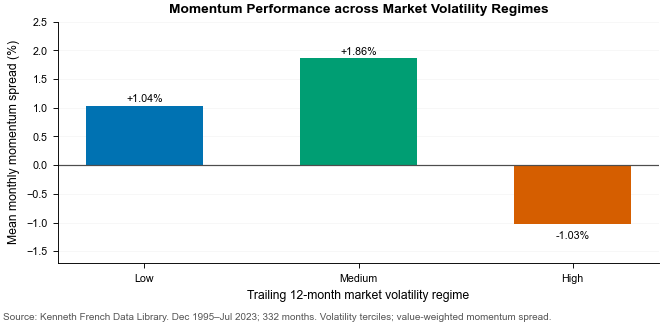

Saved: /Users/zhangjiaxin/Desktop/fe5018-final/output/figures/fig_1E_regime_momentum.png


In [10]:

# Step 9: Plot momentum performance across volatility regimes

plot_data = summary_display.loc[
    ["Low", "Medium", "High"]
].copy()

mean_returns = plot_data["Mean Momentum (%)"]

fig, ax = utils.new_fig("full")

colors = [
    config.COLORS[0],
    config.COLORS[2],
    config.COLORS[3]
]

bars = ax.bar(
    mean_returns.index.astype(str),
    mean_returns.values,
    color=colors,
    width=0.55
)

ax.axhline(0, color=config.COLOR_MARKET, linewidth=0.8)

ax.set_title("Momentum Performance across Market Volatility Regimes")
ax.set_ylabel("Mean monthly momentum spread (%)")
ax.set_xlabel("Trailing 12-month market volatility regime")

ax.set_ylim(-1.7, 2.5)
ax.grid(axis="y", alpha=0.4)
ax.grid(axis="x", visible=False)
ax.set_axisbelow(True)

for bar, value in zip(bars, mean_returns.values):
    offset = 0.12 if value >= 0 else -0.20

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + offset,
        f"{value:+.2f}%",
        ha="center",
        va="center",
        fontsize=config.FONT_SMALL
    )

fig_path = utils.save_fig(
    fig,
    "fig_1E_regime_momentum",
    source=(
        "Source: Kenneth French Data Library. "
        "Dec 1995–Jul 2023; 332 months. "
        "Volatility terciles; value-weighted momentum spread."
    )
)

plt.show()
print("Saved:", fig_path)


In [11]:

# Step 10: Export regime summary and Welch test results

regime_table = summary_display.copy()

regime_path = utils.save_table(
    regime_table,
    "tab_1E_regime_summary"
)

welch_table = pd.DataFrame({
    "Statistic": [
        "Low-vol mean momentum (%)",
        "High-vol mean momentum (%)",
        "High minus low (pp)",
        "Welch t-statistic",
        "Welch p-value"
    ],
    "Value": [
        low_mom.mean() * 100,
        high_mom.mean() * 100,
        mean_diff_pp,
        welch_result.statistic,
        welch_result.pvalue
    ]
})

welch_path = utils.save_table(
    welch_table.set_index("Statistic"),
    "tab_1E_welch_test"
)

print("Regime summary:", regime_path)
print("Welch test:", welch_path)
print("Regression:", config.TAB_DIR / "tab_1E_regression.csv")
print("Figure:", fig_path)


Regime summary: /Users/zhangjiaxin/Desktop/fe5018-final/output/tables/tab_1E_regime_summary.csv
Welch test: /Users/zhangjiaxin/Desktop/fe5018-final/output/tables/tab_1E_welch_test.csv
Regression: /Users/zhangjiaxin/Desktop/fe5018-final/output/tables/tab_1E_regression.csv
Figure: /Users/zhangjiaxin/Desktop/fe5018-final/output/figures/fig_1E_regime_momentum.png
